In [85]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/fetal_health.csv')

# Display the first few rows
df.head()


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,abc,fetal_health
0,120,0.000,0.0,0.000,0.000,0.0,0.0,73,0.5,43,...,126.0,2,0,120,137,121,73.0,1.0,4065,2
1,132,0.006,0.0,0.006,0.003,0.0,0.0,17,2.1,0,...,198.0,6,1,141,136,140,12.0,0.0,3696,1
2,133,0.003,0.0,0.008,0.003,0.0,0.0,16,2.1,0,...,198.0,5,1,141,135,138,13.0,0.0,1039,1
3,134,0.003,0.0,0.008,0.003,0.0,0.0,16,2.4,0,...,170.0,11,0,137,134,137,13.0,1.0,1439,1
4,132,0.007,0.0,0.008,0.000,0.0,0.0,16,2.4,0,...,170.0,9,0,137,136,138,11.0,1.0,3976,1


In [86]:

# Count missing values per column
missing_values = df.isnull().sum()

# Display missing values
print(missing_values)

baseline value                                               0
accelerations                                                0
fetal_movement                                               0
uterine_contractions                                         0
light_decelerations                                          8
severe_decelerations                                         8
prolongued_decelerations                                     8
abnormal_short_term_variability                              0
mean_value_of_short_term_variability                         0
percentage_of_time_with_abnormal_long_term_variability       0
mean_value_of_long_term_variability                          7
histogram_width                                              7
histogram_min                                                7
histogram_max                                             1776
histogram_number_of_peaks                                    0
histogram_number_of_zeroes                             

In [87]:
# Calculate percentage of missing values per column
missing_percentage = df.isnull().mean() * 100

# Display missing value percentages
print(missing_percentage)

baseline value                                             0.000000
accelerations                                              0.000000
fetal_movement                                             0.000000
uterine_contractions                                       0.000000
light_decelerations                                        0.376294
severe_decelerations                                       0.376294
prolongued_decelerations                                   0.376294
abnormal_short_term_variability                            0.000000
mean_value_of_short_term_variability                       0.000000
percentage_of_time_with_abnormal_long_term_variability     0.000000
mean_value_of_long_term_variability                        0.329257
histogram_width                                            0.329257
histogram_min                                              0.329257
histogram_max                                             83.537159
histogram_number_of_peaks                       

In [88]:
# Filter columns with missing values <= 35%
columns_to_keep = missing_percentage[missing_percentage <= 35].index

# Create a new DataFrame with selected columns
df_cleaned = df[columns_to_keep]

# Display the remaining columns
df_cleaned.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,abc,fetal_health
0,120,0.000,0.0,0.000,0.000,0.0,0.0,73,0.5,43,...,62.0,2,0,120,137,121,73.0,1.0,4065,2
1,132,0.006,0.0,0.006,0.003,0.0,0.0,17,2.1,0,...,68.0,6,1,141,136,140,12.0,0.0,3696,1
2,133,0.003,0.0,0.008,0.003,0.0,0.0,16,2.1,0,...,68.0,5,1,141,135,138,13.0,0.0,1039,1
3,134,0.003,0.0,0.008,0.003,0.0,0.0,16,2.4,0,...,53.0,11,0,137,134,137,13.0,1.0,1439,1
4,132,0.007,0.0,0.008,0.000,0.0,0.0,16,2.4,0,...,53.0,9,0,137,136,138,11.0,1.0,3976,1


In [89]:
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor
features = df_cleaned.drop(columns=['fetal_health'])
target = df_cleaned['fetal_health']

# Define the imputer with Random Forest as estimator
rf_estimator = RandomForestRegressor(n_estimators=10, random_state=42)

imputer = IterativeImputer(estimator=rf_estimator, random_state=42)

# Fit and transform the features to impute missing values
features_imputed = imputer.fit_transform(features)

# Convert back to DataFrame and restore columns
features_imputed_df = pd.DataFrame(features_imputed, columns=features.columns)

# Combine the imputed features with the target column
df_imputed = pd.concat([features_imputed_df, target], axis=1)

# Show the first few rows of the imputed dataset
df_imputed.head()

/usr/local/lib/python3.11/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,abc,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,4065.0,2
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,3696.0,1
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1039.0,1
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1439.0,1
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,3976.0,1


In [90]:
# Check for missing values count per column
missing_values = df_imputed.isnull().sum()

print("Missing values per column:")
print(missing_values)

Missing values per column:
baseline value                                            0
accelerations                                             0
fetal_movement                                            0
uterine_contractions                                      0
light_decelerations                                       0
severe_decelerations                                      0
prolongued_decelerations                                  0
abnormal_short_term_variability                           0
mean_value_of_short_term_variability                      0
percentage_of_time_with_abnormal_long_term_variability    0
mean_value_of_long_term_variability                       0
histogram_width                                           0
histogram_min                                             0
histogram_number_of_peaks                                 0
histogram_number_of_zeroes                                0
histogram_mode                                            0
histogram_mea

In [91]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_imputed.drop(columns=['fetal_health'])
y = df_imputed['fetal_health']

# Split the dataset: 80% train, 20% test (you can adjust test_size)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display the shape of the splits
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1700, 21)
X_test shape: (426, 21)
y_train shape: (1700,)
y_test shape: (426,)


In [92]:
import pandas as pd
from scipy.stats import f_oneway

# Assuming df_imputed is already loaded and contains the target column 'fetal_health'

# Separate features and target
features = X_train
target = y_train

# Get unique classes in the target
classes = target.unique()

# Prepare to collect p-values
p_values = {}

# Perform one-way ANOVA for each feature
for col in features.columns:
    groups = [features[col][target == cls] for cls in classes]
    stat, p = f_oneway(*groups)
    p_values[col] = p

# Convert to DataFrame for better display
p_values_df = pd.DataFrame.from_dict(p_values, orient='index', columns=['p-value'])

print(p_values_df)


                                                          p-value
baseline value                                       5.467294e-47
accelerations                                        3.728114e-63
fetal_movement                                       2.227786e-05
uterine_contractions                                 7.002738e-30
light_decelerations                                  1.293912e-20
severe_decelerations                                 1.899636e-15
prolongued_decelerations                            3.406556e-149
abnormal_short_term_variability                     2.886239e-105
mean_value_of_short_term_variability                 8.265565e-37
percentage_of_time_with_abnormal_long_term_vari...  1.573912e-103
mean_value_of_long_term_variability                  3.467244e-22
histogram_width                                      2.812734e-18
histogram_min                                        2.979738e-29
histogram_number_of_peaks                            1.608142e-04
histogram_

In [93]:
import pandas as pd
from scipy.stats import f_oneway

# Combine X_train and y_train to calculate p-values based on training data only
train_data = X_train.copy()
train_data['fetal_health'] = y_train

# Get unique classes from training target
classes = y_train.unique()

# Calculate p-values on training set
p_values = {}
for col in X_train.columns:
    groups = [train_data[col][train_data['fetal_health'] == cls] for cls in classes]
    stat, p = f_oneway(*groups)
    p_values[col] = p

# Select features with p-value < 0.05
significant_features = [feature for feature, p in p_values.items() if p < 0.05]

print(f"Features retained (p-value < 0.05): {significant_features}")

# Keep only significant features in train and test sets
X_train_filtered = X_train[significant_features]
X_test_filtered = X_test[significant_features]

print("Filtered X_train shape:", X_train_filtered.shape)
print("Filtered X_test shape:", X_test_filtered.shape)


Features retained (p-value < 0.05): ['baseline value', 'accelerations', 'fetal_movement', 'uterine_contractions', 'light_decelerations', 'severe_decelerations', 'prolongued_decelerations', 'abnormal_short_term_variability', 'mean_value_of_short_term_variability', 'percentage_of_time_with_abnormal_long_term_variability', 'mean_value_of_long_term_variability', 'histogram_width', 'histogram_min', 'histogram_number_of_peaks', 'histogram_mode', 'histogram_mean', 'histogram_median', 'histogram_variance', 'histogram_tendency']
Filtered X_train shape: (1700, 19)
Filtered X_test shape: (426, 19)


In [94]:
# Count samples per class in y_train
class_counts = y_train.value_counts()

print("Number of samples per class in the training set:")
print(class_counts)

Number of samples per class in the training set:
fetal_health
1    1323
2     236
0     141
Name: count, dtype: int64


In [95]:
from imblearn.combine import SMOTEENN

# Initialize SMOTEENN
smote_enn = SMOTEENN(random_state=42)

# Apply SMOTEENN to the training data
X_resampled, y_resampled = smote_enn.fit_resample(X_train_filtered, y_train)

# Check the new class distribution
from collections import Counter
print("Before SMOTEENN:", Counter(y_train))
print("After SMOTEENN:", Counter(y_resampled))

# X_resampled and y_resampled are your balanced training features and target


Before SMOTEENN: Counter({1: 1323, 2: 236, 0: 141})
After SMOTEENN: Counter({0: 1281, 2: 1255, 1: 1100})


In [96]:
import numpy as np
import pandas as pd

# Convert X_resampled to DataFrame if it isn't one already
if not isinstance(X_resampled, pd.DataFrame):
    X_resampled = pd.DataFrame(X_resampled, columns=X_train_filtered.columns)

# Find rows with any negative values
negative_rows = (X_resampled < 0).any(axis=1)

# Filter out those rows from X_resampled and corresponding y_resampled
X_resampled_clean = X_resampled[~negative_rows]
y_resampled_clean = y_resampled[~negative_rows]

print(f"Removed {negative_rows.sum()} records with negative values.")
print(f"Remaining records: {X_resampled_clean.shape[0]}")

# Now X_resampled_clean and y_resampled_clean have no negative values


Removed 595 records with negative values.
Remaining records: 3041


In [97]:
X_resampled, y_resampled=X_resampled_clean, y_resampled_clean

from sklearn.feature_selection import SelectKBest, chi2

# Initialize SelectKBest with chi2 to select top 5 features
selector = SelectKBest(score_func=chi2, k=7)

# Fit selector on the resampled training data
X_resampled_selected = selector.fit_transform(X_resampled, y_resampled)

# Apply the same feature selection to the test set
X_test_selected = selector.transform(X_test_filtered)

# Get the selected feature names
selected_features = X_resampled.columns[selector.get_support()]

print("Selected features:", list(selected_features))

# X_resampled_selected and X_test_selected now have only the selected features


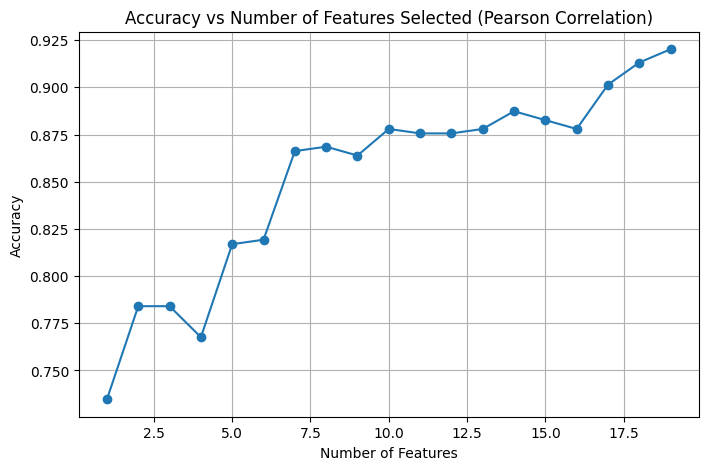

In [98]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Assuming:
# - X_resampled and y_resampled are your balanced train data (pandas DataFrame and Series)
# - X_test_filtered and y_test are your test data and labels

# Encode y_resampled for correlation
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y_resampled)

# Calculate absolute Pearson correlations
correlations = []
for col in X_resampled.columns:
    corr = np.corrcoef(X_resampled[col], y_encoded)[0, 1]
    correlations.append(abs(corr))

corr_series = pd.Series(correlations, index=X_resampled.columns)
corr_series = corr_series.sort_values(ascending=False)

accuracies = []
feature_counts = list(range(1, len(corr_series) + 1))

for k in feature_counts:
    selected_features = corr_series.head(k).index.tolist()

    # Select features for train and test
    X_train_sel = X_resampled[selected_features]
    X_test_sel = X_test_filtered[selected_features]

    # Train Random Forest
    rf = RandomForestClassifier(random_state=42)
    rf.fit(X_train_sel, y_resampled)

    # Predict and compute accuracy
    y_pred = rf.predict(X_test_sel)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

# Plot accuracy vs number of features
plt.figure(figsize=(8,5))
plt.plot(feature_counts, accuracies, marker='o')
plt.title('Accuracy vs Number of Features Selected (Pearson Correlation)')
plt.xlabel('Number of Features')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()


In [104]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define the parameter grid for Randomized Search
param_dist = {
    'n_estimators': randint(50, 300),          # number of trees
    'max_depth': randint(5, 50),                # max depth of trees
    'min_samples_split': randint(2, 20),       # minimum samples to split node
    'min_samples_leaf': randint(1, 20),        # minimum samples at leaf node
    'max_features': ['auto', 'sqrt', 'log2', None],  # features considered at split
    'bootstrap': [True, False]
}

# Initialize the classifier
rf = RandomForestClassifier(random_state=42)

# Setup RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=5,                # number of parameter settings sampled
    cv=5,                     # 5-fold cross-validation
    verbose=2,
    random_state=42,
    n_jobs=-1                 # use all cores
)

# Fit RandomizedSearchCV on the training data
random_search.fit(X_resampled_clean, y_resampled_clean)

# Print best parameters and best score
print("Best parameters found:")
print(random_search.best_params_)

print(f"Best cross-validation score: {random_search.best_score_:.4f}")


Fitting 5 folds for each of 5 candidates, totalling 25 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
5 fits failed out of a total of 25.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.11/dist-packages/sklearn/utils/_pa

Best parameters found:
{'bootstrap': False, 'max_depth': 34, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 253}
Best cross-validation score: 0.9915


In [105]:
X_test_selected.shape

(426, 7)

In [106]:
X_resampled_clean.shape

(3041, 19)

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.94      0.85        35
           1       0.99      0.89      0.94       332
           2       0.63      0.92      0.74        59

    accuracy                           0.90       426
   macro avg       0.80      0.92      0.84       426
weighted avg       0.92      0.90      0.90       426

Confusion Matrix:
[[ 33   0   2]
 [  7 295  30]
 [  3   2  54]]


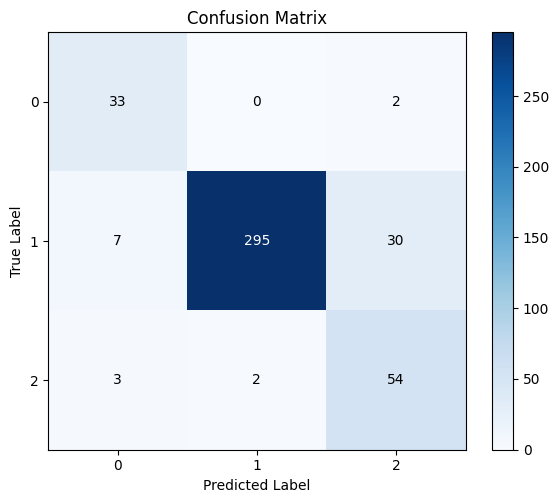

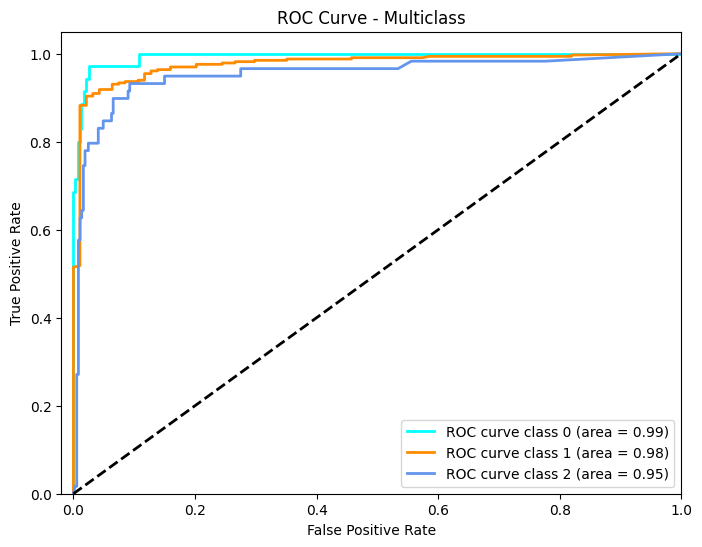

In [107]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

# Assumptions:
# - X_resampled_clean, y_resampled_clean: cleaned, balanced training data
# - X_test_selected: test data with selected features
# - y_test: true labels for the test set
# - random_search.best_params_ contains the best hyperparameters found

# Train Random Forest classifier with best parameters
best_rf = RandomForestClassifier(**random_search.best_params_, random_state=42)
best_rf.fit(X_resampled_selected, y_resampled_clean)

# Predict class labels and probabilities on the test set
y_pred = best_rf.predict(X_test_selected)
y_proba = best_rf.predict_proba(X_test_selected)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.colorbar()

classes = np.unique(y_test)
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes)
plt.yticks(tick_marks, classes)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Annotate cells with counts
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.show()

# ROC curve for multiclass classification

# Binarize the true labels for ROC calculation
y_test_binarized = label_binarize(y_test, classes=classes)
n_classes = y_test_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves for all classes
plt.figure(figsize=(8, 6))
colors = ['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple']  # add more if needed

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve class {classes[i]} (area = {roc_auc[i]:0.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Multiclass')
plt.legend(loc="lower right")
plt.show()
